# Presentation: No Market Scenario Capabilities

In [ ]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch

file = 'Figures/SI'

if not os.path.exists(file):
    os.makedirs(file)


# ---------- Helper functions ----------

def create_dataframe(path, tag):
    """Create a dict of dataframes from CSV files in path, keyed by WWTP name."""
    files = os.listdir(path)
    dfs = {}
    for file in files:
        if file.endswith('.csv'):
            df = pd.read_csv(path + file)
            if tag == 'results':
                if 'results' not in file:
                    continue
                WWTP = file.split('results_')[1]
                WWTP = WWTP.split('.csv')[0]
                if 'econ' not in WWTP:
                    dfs[WWTP] = df
            elif tag in file:
                WWTP = file.split('results_' + tag + '_')[1]
                WWTP = WWTP.split('.csv')[0]
                dfs[WWTP] = df
    return dfs


def create_df(WWTP, dfs):
    """Extract a single WWTP dataframe from dfs dict and parse Datetime."""
    df = dfs[WWTP].copy()
    df.rename(columns={df.columns[0]: 'Datetime'}, inplace=True)
    df['Datetime'] = pd.to_datetime(df['Datetime'])
    return df


def create_df_finance_econ(path, WWTPs):
    """Merge annual econ and finance CSVs for all WWTPs into one dataframe."""
    df_all = pd.DataFrame()
    for WWTP in WWTPs:
        path_finance = path + f'results_finance_{WWTP}.csv'
        path_econ    = path + f'results_econ_{WWTP}.csv'
        df_finance = pd.read_csv(path_finance, index_col=0).reset_index().rename(columns={'index': 'Year'})
        df_econ    = pd.read_csv(path_econ,    index_col=0).reset_index().rename(columns={'index': 'Year'})
        df_w = pd.merge(df_econ, df_finance, on='Year', how='left', suffixes=('_NPV', '_finance'))
        df_w['WWTP'] = WWTP
        df_all = pd.concat([df_all, df_w], axis=0)
    return df_all


In [ ]:
# ---------- Paths ----------

path_NC = 'Results/Sensitivity_maxCredit_exchange_market_TR_1.0/No_coordination/'
path_FC = 'Results/Sensitivity_maxCredit_exchange_market_TR_1.0/Full_coordination_hotspot_0_yr_constrain_credits_bought/300/'
WWTPs = ['SJSC', 'Sunnyvale', 'Palo Alto']

# Annual data (econ + finance merged) — contains {L}_built columns for schedule
df_NC = create_df_finance_econ(path_NC, WWTPs)
df_FC = create_df_finance_econ(path_FC, WWTPs)

# Monthly results — contains {L}_per_removal, {L}_per_lim
dfs_NC_results = create_dataframe(path_NC, tag='results')
df_FC_results = create_dataframe(path_FC, tag='results')

# Annual econ — contains {L}_opex, {L}_capex
dfs_NC_econ = create_dataframe(path_NC, tag='econ')
df_FC_results = create_dataframe(path_FC, tag='results')

print('Data loaded for WWTPs:', WWTPs)
print('df_NC columns (sample):', list(df_NC.columns[:10]))


Data loaded for WWTPs: ['SJSC', 'Sunnyvale', 'Palo Alto']
df_NC columns (sample): ['Year', 'Total_capex', 'Total_opex', 'Sold_credits_NPV', 'Bought_credits_NPV', 'Unit_cost_NPV', 'Avg_abatement_cost_NPV', 'Total_credits_sell', 'Total_credits_buy', 'SS_constructed']


In [50]:
# ---------- Plot settings (matching Fig_1.ipynb) ----------

Ls        = ['SS', 'L2', 'L2upg3', 'L3']

custom_colors    = {'L3': '#726DA8', 'L2': '#484538', 'SS': '#CAD49D', 'L2upg3': '#EB5E28'}
custom_hatches   = {'L3': '//',      'L2': '',         'SS': '',        'L2upg3': '\\\\'}
custom_edgecolor = {'L3': 'white',   'L2': 'none',     'SS': 'none',    'L2upg3': 'black'}
color_total      = '#EB5E28'

hfont       = {'fontname': 'Helvetica', 'size': 8}
hfont_ticks = {'fontname': 'Helvetica', 'size': 7}
leg_size    = 6
lab_size    = 7
line_wid    = 1
bord_wid    = 2


def plot_NC_capabilities(WWTP, lim_opex=2, lim_capex=150):
    """
    Four-subplot figure for the No Market (NC) scenario.
    All subplots share an integer-year x-axis so the schedule rectangles
    (drawn at integer year coordinates) align with the step plots.
      [0] Upgrade schedule (Gantt-style, NC only) — y-labels are Ls
      [1] TIN Removal (%)
      [2] Opex ($mil/year)
      [3] Capex ($mil)
    """
    fig, axs = plt.subplots(4, 1, figsize=(120/25.4, 120/25.4))

    # ── Subplot 0: Schedule (NC only) ──────────────────────────────────────
    # Rectangles are drawn at integer year positions; x-axis must stay integer
    df_w_NC  = df_NC[df_NC['WWTP'] == WWTP].copy()
    years_NC = pd.to_datetime(df_w_NC['Year']).dt.year.values

    for y_pos, L in enumerate(Ls):
        # ── Operational patch (solid fill) ──
        col_built = f'{L}_built'
        if col_built in df_w_NC.columns:
            sched = df_w_NC[col_built].values
            if sched.sum() > 0:
                start = years_NC[sched.argmax()]
                end   = years_NC[sched.nonzero()[0][-1]]
                axs[0].add_patch(Rectangle(
                    (start, y_pos - 0.4), end - start, 0.8,
                    facecolor=custom_colors[L],
                    hatch=custom_hatches[L],
                    edgecolor=custom_edgecolor[L],
                    lw=0.2
                ))

        # ── Construction patch (hatched, right before operational) ──
        col_const = f'{L}_construction'
        if col_const in df_w_NC.columns:
            under_construction = df_w_NC[col_const].values
            if under_construction.sum() > 0:
                c_start = years_NC[under_construction.argmax()]
                c_end   = years_NC[under_construction.nonzero()[0][-1]]
                axs[0].add_patch(Rectangle(
                    (c_start, y_pos - 0.4), c_end - c_start + 1, 0.8,
                    facecolor=custom_colors[L],
                    alpha=1,
                    hatch='xxx',
                    edgecolor='black',
                    lw=0.2
                ))

    legend_handles = [
        Patch(facecolor=custom_colors[L], hatch=custom_hatches[L],
              edgecolor=custom_edgecolor[L], linewidth=0.2, label=L)
        for L in Ls
    ] + [
        Patch(facecolor='grey', alpha=0.4, hatch='xxx',
              edgecolor='black', linewidth=0.2, label='Under construction')
    ]
    axs[0].legend(
        handles=legend_handles,
        loc='lower center', bbox_to_anchor=(0.5, 1.02),
        ncol=len(Ls) + 1, frameon=False,
        prop={'family': 'Helvetica', 'size': leg_size}
    )
    axs[0].set_ylim(-0.5, len(Ls) - 0.5)
    axs[0].set_yticks(range(len(Ls)))
    axs[0].set_yticklabels(Ls, **hfont_ticks)
    #axs[0].set_ylabel('Treatment upgrade', **hfont)
    axs[0].tick_params(axis='y', pad=5)

    # ── Subplot 1: TIN Removal (%) ─────────────────────────────────────────
    # Monthly data converted to fractional year to share integer-year x-axis
    df_res    = create_df(WWTP, dfs_NC_results)
    x_monthly = df_res.Datetime.dt.year + (df_res.Datetime.dt.month - 1) / 12

    for L in Ls:
        col_rem = f'{L}_per_removal'
        col_lim = f'{L}_per_lim'
        if col_rem not in df_res.columns:
            continue
        axs[1].step(x_monthly, df_res[col_rem], '-',
                    color=custom_colors[L], label='', where='post', linewidth=line_wid)
        if col_lim in df_res.columns:
            mask = df_res.Datetime >= '2035-01-01'
            if mask.any():
                axs[1].plot(x_monthly[mask], df_res.loc[mask, col_lim], '--',
                            color=custom_colors[L], linewidth=line_wid,
                            label=('Upgrade removal limit' if L == 'L3' else ''))

    axs[1].set_ylabel('TIN Removal\n(%)', **hfont)
    axs[1].set_ylim(0, 100)
    axs[1].legend(loc='upper left', frameon=False,
                  bbox_to_anchor=(0, 0.8), prop={'family': 'Helvetica', 'size': leg_size})

    # ── Subplot 2: Opex ────────────────────────────────────────────────────
    # Annual econ data — use integer year as x
    df_econ  = create_df(WWTP, dfs_NC_econ)
    x_annual = df_econ.Datetime.dt.year

    valid_Ls_opex = [L for L in Ls if f'{L}_opex' in df_econ.columns]
    for L in valid_Ls_opex:
        vals = df_econ[f'{L}_opex'].values
        axs[2].step(x_annual, np.append(vals[:-1], vals[-2]), '-',
                    color=custom_colors[L], where='post', linewidth=line_wid)

    opex_arr = sum(df_econ[f'{L}_opex'] for L in valid_Ls_opex).values
    axs[2].step(x_annual, np.append(opex_arr[:-1], opex_arr[-2]),
                linestyle='dashdot', color=color_total, label='Total opex',
                where='post', linewidth=line_wid)
    axs[2].set_ylabel('Opex\n(PV $mil)', **hfont)
    axs[2].set_ylim(0, lim_opex)
    axs[2].legend(loc='upper left', frameon=False,
                  bbox_to_anchor=(0, 0.8), prop={'family': 'Helvetica', 'size': leg_size})

    # ── Subplot 3: Capex ───────────────────────────────────────────────────
    valid_Ls_capex = [L for L in Ls if f'{L}_capex' in df_econ.columns]
    for L in valid_Ls_capex:
        axs[3].step(x_annual, df_econ[f'{L}_capex'], '-',
                    color=custom_colors[L], label='', where='post', linewidth=line_wid)

    cum_capex, cum_val = [], 0
    for j in range(len(df_econ)):
        cum_val += sum(df_econ[f'{L}_capex'].iloc[j] for L in valid_Ls_capex)
        cum_capex.append(cum_val)
    axs[3].step(x_annual, cum_capex,
                linestyle='dashdot', color=color_total, label='Cumulative capex',
                where='post', linewidth=line_wid)
    axs[3].set_ylabel('Capex\n(PV $mil)', **hfont)
    axs[3].set_ylim(0, lim_capex)
    axs[3].set_xlabel('Year', **hfont)
    axs[3].legend(loc='best', frameon=False,
                prop={'family': 'Helvetica', 'size': leg_size})

    # ── Shared integer-year x-axis formatting ──────────────────────────────
    # All 4 subplots now use integer years so limits and ticks are consistent
    x_lo    = years_NC[0]
    x_hi    = years_NC[30] + 1
    x_ticks = np.arange(years_NC[0], years_NC[30] + 1, 5)

    x_label_coord = -0.07
    fig_labels    = ['i', 'ii', 'iii', 'iv']
    for i, ax in enumerate(axs):
        ax.set_xlim(x_lo, x_hi)
        ax.set_xticks(x_ticks)
        if i == len(axs) - 1:
            ax.set_xticklabels(x_ticks, **hfont_ticks)
        else:
            ax.set_xticklabels([])
        ax.yaxis.set_label_coords(x_label_coord, 0.5)
        ax.text(0.02, 0.9, fig_labels[i], transform=ax.transAxes,
                fontsize=leg_size, fontweight='bold', va='top', ha='left')
        ax.xaxis.set_ticks_position('both')
        ax.tick_params(axis='both', which='major', labelsize=leg_size,
                       labelfontfamily='Helvetica')
        ax.tick_params(axis='both', width=line_wid, length=bord_wid)
        for spine in ax.spines.values():
            spine.set_linewidth(line_wid)

    #fig.suptitle(f'{WWTP} — No Market Scenario', **hfont, y=1.01)
    fig.tight_layout()
    plt.show()
    fig.savefig(f'{file}/NC_{WWTP}.svg', dpi=300, bbox_inches='tight')
    return fig


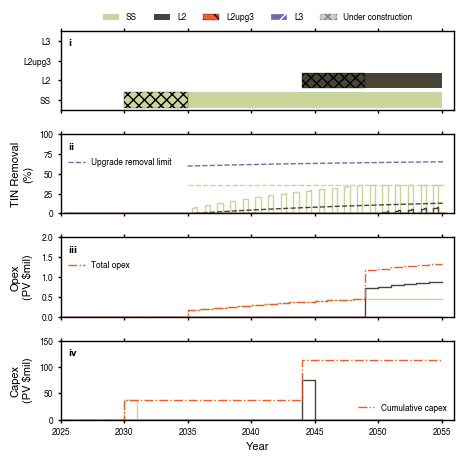

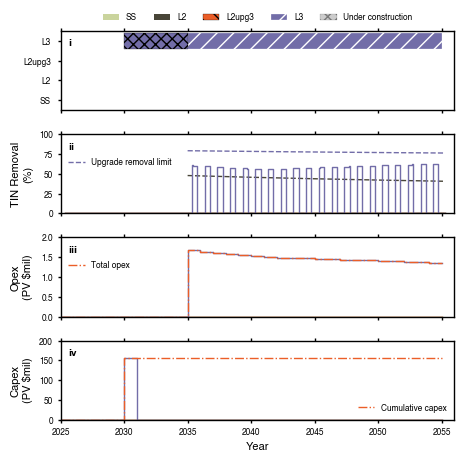

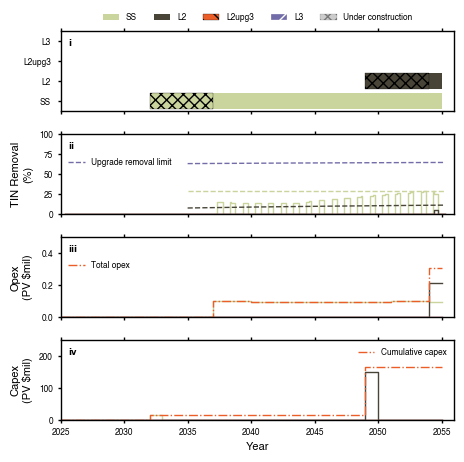

In [51]:
fig_SJSC = plot_NC_capabilities('SJSC', lim_opex=2, lim_capex=150)
fig_PA = plot_NC_capabilities('Palo Alto', lim_opex=2, lim_capex=200)
fig_SV = plot_NC_capabilities('Sunnyvale', lim_opex=0.5, lim_capex=250)


In [69]:
def plot_schedule(path, WWTPs=WWTPs, name='schedule', fig_label= '', legend=True):
    """
    Gantt-style upgrade schedule for all WWTPs in a single axis.
    Each WWTP gets its own block of len(Ls) rows (one row per L); the y-ticks
    only label the WWTPs, centred on their block. Legend of Ls sits on top.
      path : folder passed to create_df_finance_econ(path, WWTPs)
      name : file name (without extension) for the saved figure
    """
    df = create_df_finance_econ(path, WWTPs)
    WWTP_list = ['Palo Alto', 'SJSC', 'Sunnyvale']

    n_Ls    = len(Ls)
    block   = n_Ls + 1          # rows per WWTP block (+1 row gap between WWTPs)
    fig, ax = plt.subplots(1, 1, figsize=(120/25.4, (25 + 12*len(WWTPs))/25.4))

    for i, WWTP in enumerate(WWTP_list):
        df_w  = df[df['WWTP'] == WWTP].copy()
        years = pd.to_datetime(df_w['Year']).dt.year.values
        y_off = i * block

        for j, L in enumerate(Ls):
            y_pos = y_off + j

            # ── Operational patch (solid fill) ──
            col_built = f'{L}_built'
            if col_built in df_w.columns:
                sched = df_w[col_built].values
                if sched.sum() > 0:
                    start = years[sched.argmax()]
                    end   = years[sched.nonzero()[0][-1]]
                    ax.add_patch(Rectangle(
                        (start, y_pos - 0.4), end - start, 0.8,
                        facecolor=custom_colors[L],
                        hatch=custom_hatches[L],
                        edgecolor=custom_edgecolor[L],
                        lw=0.2
                    ))

            # ── Construction patch (hatched, right before operational) ──
            col_const = f'{L}_construction'
            if col_const in df_w.columns:
                under_construction = df_w[col_const].values
                if under_construction.sum() > 0:
                    c_start = years[under_construction.argmax()]
                    c_end   = years[under_construction.nonzero()[0][-1]]
                    ax.add_patch(Rectangle(
                        (c_start, y_pos - 0.4), c_end - c_start + 1, 0.8,
                        facecolor='grey',
                        alpha=0.4,
                        hatch='xxx',
                        edgecolor='black',
                        lw=0.2
                    ))

            # ── Cost label: sum of {L}_capex_lumpsum, left of the first patch ──
            col_cost = f'{L}_capex_lumpsum'
            if col_cost in df_w.columns:
                cost = df_w[col_cost].sum()
                starts = [years[df_w[col].values.argmax()]
                          for col in (col_built, col_const)
                          if col in df_w.columns and df_w[col].values.sum() > 0]
                if cost > 0 and starts:
                    ax.text(min(starts) - 0.3, y_pos, f'${round(cost)} mil',
                            ha='right', va='center',
                            fontsize=leg_size, fontname='Helvetica')

        # Dotted separator between WWTP blocks
        if i < len(WWTPs) - 1:
            ax.axhline(y_off + n_Ls, color='black', linewidth=0.5, linestyle=':')

    legend_handles = [
        Patch(facecolor=custom_colors[L], hatch=custom_hatches[L],
              edgecolor=custom_edgecolor[L], linewidth=0.2, label=L)
        for L in Ls
    ] + [
        Patch(facecolor='grey', alpha=0.4, hatch='xxx',
              edgecolor='black', linewidth=0.2, label='Under construction')
    ]
    if legend:
        ax.legend(
            handles=legend_handles,
            loc='lower center', bbox_to_anchor=(0.5, 1.02),
            ncol=n_Ls + 1, frameon=False,
            prop={'family': 'Helvetica', 'size': leg_size}
        )

    # y-ticks: WWTP labels only, centred on each block; first WWTP on top
    ax.set_ylim(-0.7, (len(WWTPs) - 1) * block + n_Ls - 0.3)
    ax.set_yticks([i * block + (n_Ls - 1) / 2 for i in range(len(WWTPs))])
    ax.set_yticklabels(WWTP_list, **hfont_ticks)
    ax.invert_yaxis()
    ax.tick_params(axis='y', pad=5)

    # ── Integer-year x-axis formatting ─────────────────────────────────────
    x_lo    = years[0]
    x_hi    = years[30] + 1
    x_ticks = np.arange(years[0], years[30] + 1, 5)
    ax.set_xlim(x_lo, x_hi)
    ax.set_xticks(x_ticks)
    ax.set_xticklabels(x_ticks, **hfont_ticks)
    ax.set_xlabel('Year', **hfont)
    ax.xaxis.set_ticks_position('both')
    ax.tick_params(axis='both', which='major', labelsize=leg_size,
                   labelfontfamily='Helvetica')
    ax.tick_params(axis='both', width=line_wid, length=bord_wid)
    ax.text(0.02, 0.95, fig_label, transform=ax.transAxes,
                    fontsize=leg_size, fontweight='bold', va='top', ha='left')
    for spine in ax.spines.values():
        spine.set_linewidth(line_wid)

    fig.tight_layout()
    plt.show()
    fig.savefig(f'{file}/{name}.svg', dpi=300, bbox_inches='tight')
    return fig

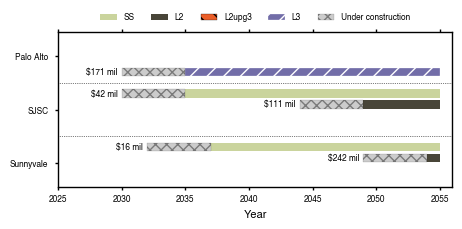

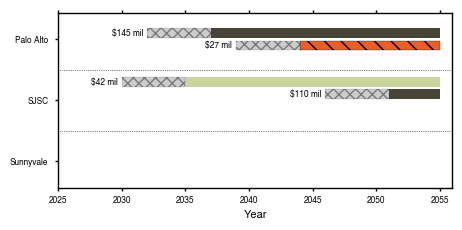

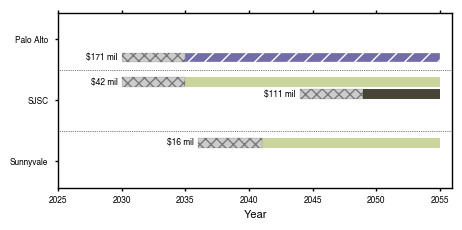

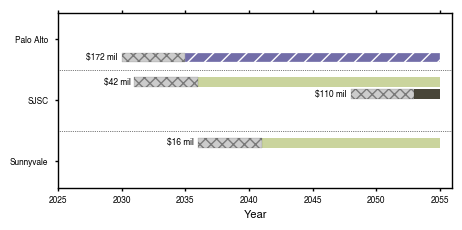

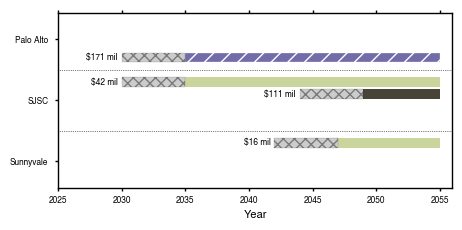

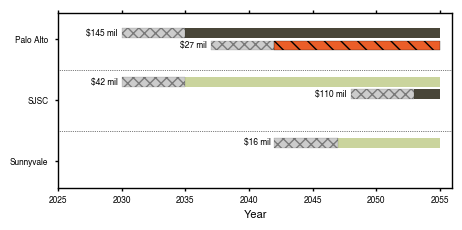

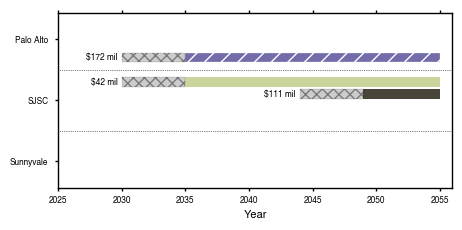

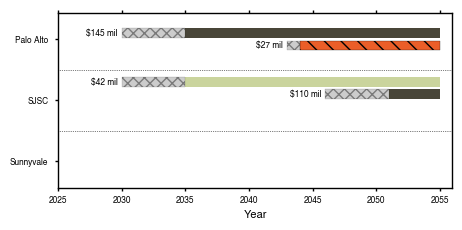

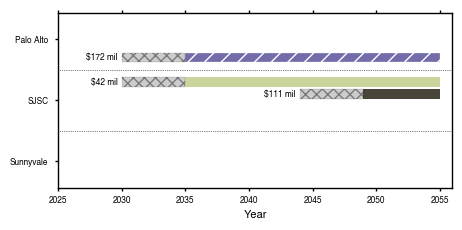

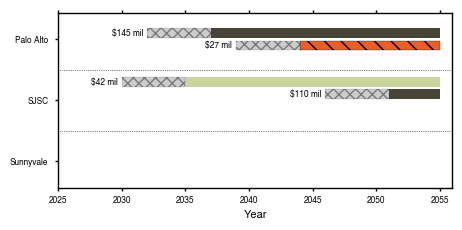

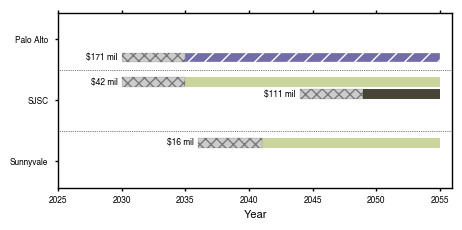

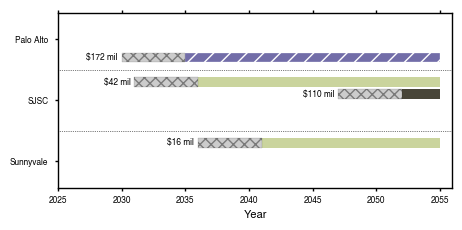

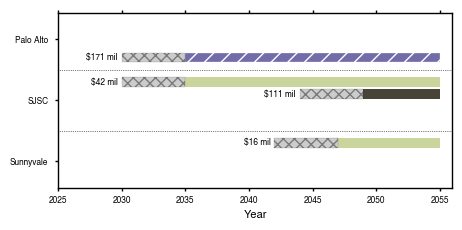

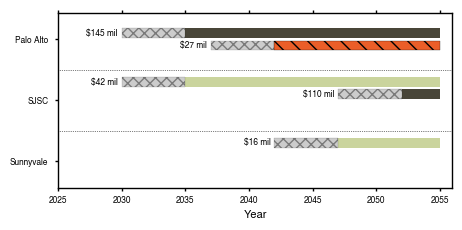

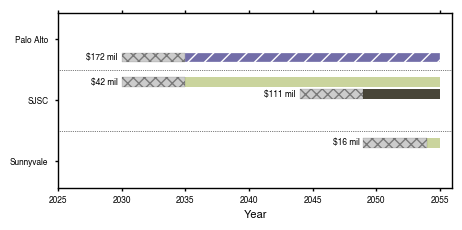

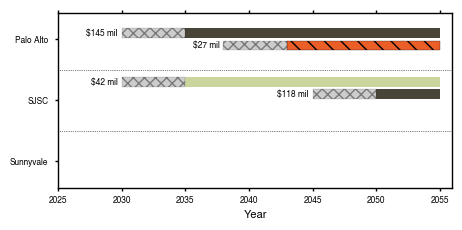

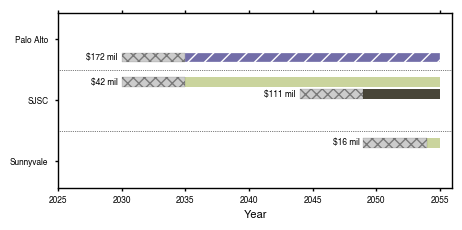

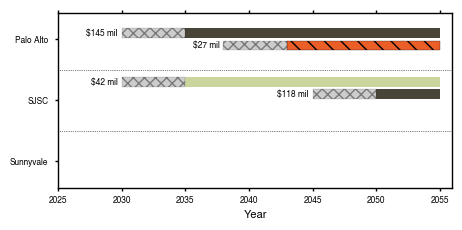

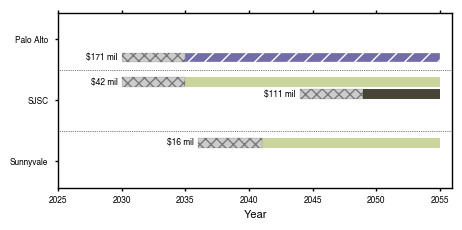

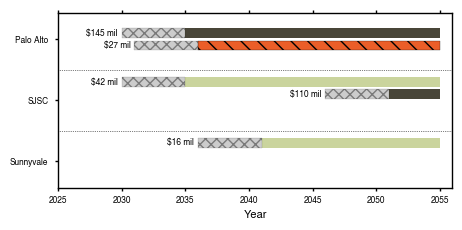

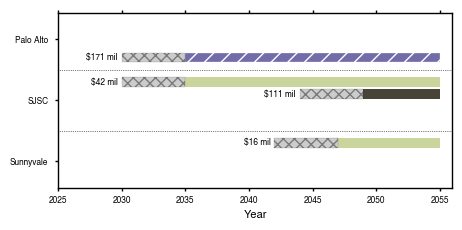

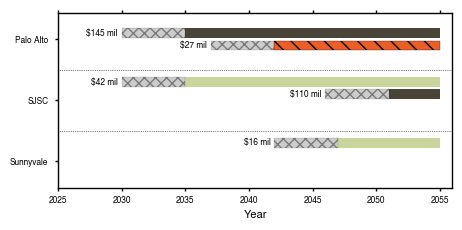

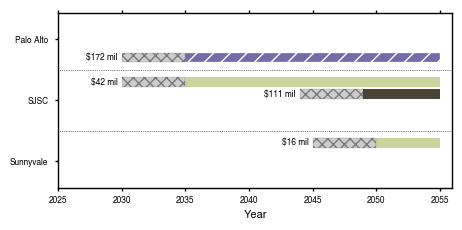

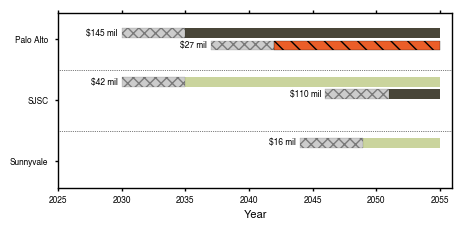

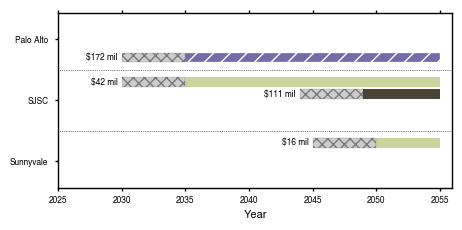

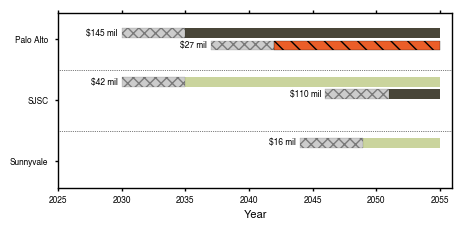

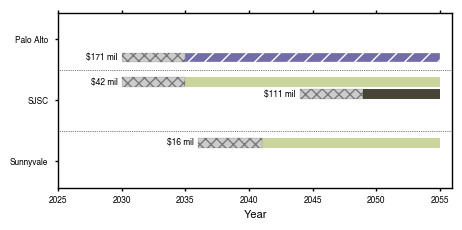

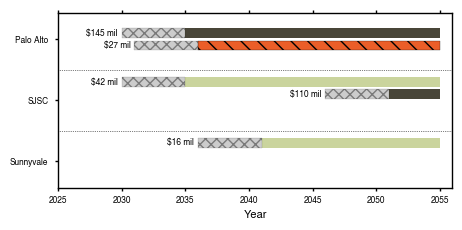

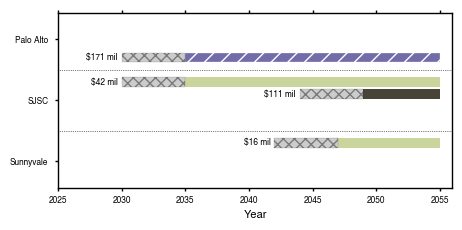

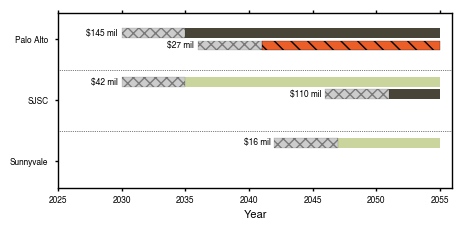

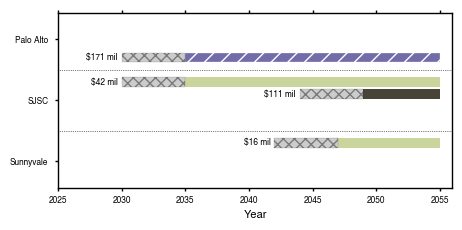

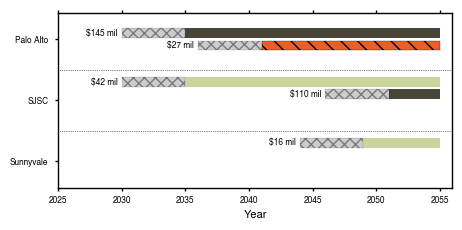

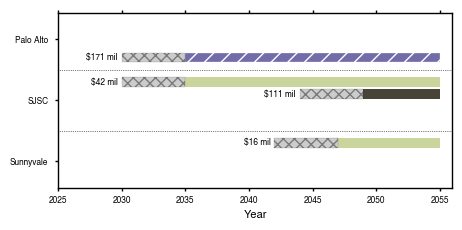

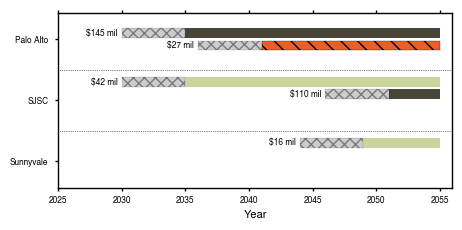

In [ ]:
path_NC = 'Results/Sensitivity_maxCredit_exchange_market_TR_1.0/No_coordination/'
path_FC = 'Results/Sensitivity_maxCredit_exchange_market_TR_1.0/Full_coordination_hotspot_0_yr_constrain_credits_bought/300/'

fig_sched_NC = plot_schedule(path_NC, WWTPs, name='schedule_NC', legend=True)
fig_sched_FC = plot_schedule(path_FC, WWTPs, name='schedule_FC', legend=False)
TRs = [1.0, 1.5, 2.0, 2.5]
HPs = [0.1, 0.25, 0.5, 300]
#TRs = [1.0]
#HPs = [300]
path_bilat = 'Results/Sensitivity_maxCredit_bilat_contract_30yrs_TR_'
path_centralized = 'Results/Sensitivity_maxCredit_exchange_market_TR_'
paths_bilat = {}
paths_CM = {}

fig_labels = {300: 'i', 0.5 : 'ii', 0.25: 'iii', 0.1: 'iv'}

for TR in TRs:
    for HP in HPs:
        path_bilat_TR = f'{path_bilat}{TR}/Full_coordination_hotspot_0_yr_constrain_credits_bought/{HP}/'
        path_centralized_TR = f'{path_centralized}{TR}/Full_coordination_hotspot_0_yr_constrain_credits_bought/{HP}/'
        paths_bilat[(TR, HP)] = path_bilat_TR
        paths_CM[(TR, HP)] = path_centralized_TR
        if not os.path.exists(file+'/schedules'):
            os.makedirs(file+'/schedules')
        fig_sched_bilat = plot_schedule(path_bilat_TR, WWTPs, name=f'schedules/schedule_bilat_TR_{TR}_HP_{HP}', fig_label= '', legend=False)
        fig_sched_CM = plot_schedule(path_centralized_TR, WWTPs, name=f'schedules/schedule_CM_TR_{TR}_HP_{HP}', fig_label= '', legend=False)


In [25]:
color_NC = '#484538'
color_FC = color_total
markers = {'SJSC':'o', 'Sunnyvale':'^', 'Palo Alto':'s'}
colors_WWTP = {'Sunnyvale': '#B79BB8', 'SJSC': '#D57A6E', 'Palo Alto': '#A3B89C'}

def plot_FC_capabilities(WWTP, lim_treated=1400, lim_cost=10, lim_price=30):
    """
    Four-subplot figure for the Full Coordination (FC) market scenario.
    All subplots share an integer-year x-axis so the schedule rectangles
    (drawn at integer year coordinates) align with the step plots.
      [0] Upgrade schedule (Gantt-style) — y-labels are Ls
      [1] TIN Removed ('1,000 lb/day), from Annual_treated
      [2] Annual capex + opex ($mil/year), each in its own color
      [3] Credit price ($/lb), (capex + opex) / annual treated
    """
    fig, axs = plt.subplots(4, 1, figsize=(120/25.4, 120/25.4))

    # ── Subplot 0: Schedule ─────────────────────────────────────────────────
    # Rectangles are drawn at integer year positions; x-axis must stay integer
    df_w_FC  = df_FC[df_FC['WWTP'] == WWTP].copy()
    years_FC = pd.to_datetime(df_w_FC['Year']).dt.year.values

    for y_pos, L in enumerate(Ls):
        # ── Operational patch (solid fill) ──
        col_built = f'{L}_built'
        if col_built in df_w_FC.columns:
            sched = df_w_FC[col_built].values
            if sched.sum() > 0:
                start = years_FC[sched.argmax()]
                end   = years_FC[sched.nonzero()[0][-1]]
                axs[0].add_patch(Rectangle(
                    (start, y_pos - 0.4), end - start, 0.8,
                    facecolor=custom_colors[L],
                    hatch=custom_hatches[L],
                    edgecolor=custom_edgecolor[L],
                    lw=0.2
                ))

        # ── Construction patch (hatched, right before operational) ──
        col_const = f'{L}_construction'
        if col_const in df_w_FC.columns:
            under_construction = df_w_FC[col_const].values
            if under_construction.sum() > 0:
                c_start = years_FC[under_construction.argmax()]
                c_end   = years_FC[under_construction.nonzero()[0][-1]]
                axs[0].add_patch(Rectangle(
                    (c_start, y_pos - 0.4), c_end - c_start + 1, 0.8,
                    facecolor=custom_colors[L],
                    alpha=1,
                    hatch='xxx',
                    edgecolor='black',
                    lw=0.2
                ))

    legend_handles = [
        Patch(facecolor=custom_colors[L], hatch=custom_hatches[L],
              edgecolor=custom_edgecolor[L], linewidth=0.2, label=L)
        for L in Ls
    ] + [
        Patch(facecolor='grey', alpha=0.4, hatch='xxx',
              edgecolor='black', linewidth=0.2, label='Under construction')
    ]
    axs[0].legend(
        handles=legend_handles,
        loc='lower center', bbox_to_anchor=(0.5, 1.02),
        ncol=len(Ls) + 1, frameon=False,
        prop={'family': 'Helvetica', 'size': leg_size}
    )
    axs[0].set_ylim(-0.5, len(Ls) - 0.5)
    axs[0].set_yticks(range(len(Ls)))
    axs[0].set_yticklabels(Ls, **hfont_ticks)
    #axs[0].set_ylabel('Treatment upgrade', **hfont)
    axs[0].tick_params(axis='y', pad=5)

    # ── Subplot 1: Annual capex + opex ──────────────────────────────────────
    x_annual  = years_FC
    capex = df_w_FC['Annual_capex'].values
    opex  = df_w_FC['Annual_opex'].values
    axs[1].step(x_annual, capex, '-',
                color=custom_colors['L3'], label='Capex', where='mid', linewidth=line_wid)
    axs[1].step(x_annual, np.append(opex[:-1], opex[-2]), '-',
                color=custom_colors['L2upg3'], label='Opex', where='mid', linewidth=line_wid)
    axs[1].set_ylabel('Total costs\n($mil/year)', **hfont)
    axs[1].set_ylim(0, lim_cost)
    axs[1].legend(loc='upper left', frameon=False,
                    bbox_to_anchor=(0, 0.8), prop={'family': 'Helvetica', 'size': leg_size})


    # ── Subplot 1: TIN Removed ('1,000 lb/day) ──────────────────────────────
    # Annual_treated is a lb/day rate; *30 converts it to lbs, /1000 to '1,000 lb
    treated   = df_w_FC['Annual_treated'].values * 30 / 1000
    sold_FC = df_w_FC['Total_units_sold'].values * 30 / 1000
    bar_width = 0.6
    axs[2].step(x_annual, treated, '-',
                color=color_total, where='mid', linewidth=line_wid, label='TIN removed')
    axs[2].bar(x_annual, sold_FC, width=bar_width, color=color_FC, label='Credits sold')
    axs[2].set_ylabel("TIN \n('1,000 lb/day)", **hfont)
    axs[2].set_ylim(0, lim_treated)
    axs[2].legend(loc='upper left', frameon=False,
                  bbox_to_anchor=(0, 0.8), prop={'family': 'Helvetica', 'size': leg_size})  
    

    # ── Subplot 3: Credit price ($/lb) ──────────────────────────────────────
    # (capex + opex in $) / annual treated (lbs); capex & opex are in $mil
    annual_treated_lb = df_w_FC['Annual_treated'].values * 30
    with np.errstate(divide='ignore', invalid='ignore'):
        production_cost = np.where(annual_treated_lb > 0,
                                 (capex + opex) * 1e6 / annual_treated_lb,
                                 np.nan)
        credit_price = np.where(sold_FC > 0,
                                 (capex + opex) * 1e6 / annual_treated_lb,
                                 np.nan)
    axs[3].step(x_annual, production_cost,
                        color=color_total, where='mid', linewidth=line_wid, label= 'Average production cost')
    axs[3].scatter(x_annual, credit_price,
                    color=colors_WWTP[WWTP], marker=markers[WWTP], s=20, label=f'{WWTP} credit price')
    axs[3].set_ylabel('Price\n($/lb)', **hfont)
    axs[3].set_ylim(0, lim_price)
    axs[3].set_xlabel('Year', **hfont)
    axs[3].legend(loc='upper left', frameon=False,
                  bbox_to_anchor=(0, 0.8), prop={'family': 'Helvetica', 'size': leg_size})

    # ── Shared integer-year x-axis formatting ───────────────────────────────
    # All 4 subplots now use integer years so limits and ticks are consistent
    x_lo    = years_FC[0]
    x_hi    = years_FC[30] + 1
    x_ticks = np.arange(years_FC[0], years_FC[30] + 1, 5)

    x_label_coord = -0.07
    fig_labels    = ['i', 'ii', 'iii', 'iv']
    for i, ax in enumerate(axs):
        ax.set_xlim(x_lo, x_hi)
        ax.set_xticks(x_ticks)
        if i == len(axs) - 1:
            ax.set_xticklabels(x_ticks, **hfont_ticks)
        else:
            ax.set_xticklabels([])
        ax.yaxis.set_label_coords(x_label_coord, 0.5)
        ax.text(0.02, 0.9, fig_labels[i], transform=ax.transAxes,
                fontsize=leg_size, fontweight='bold', va='top', ha='left')
        ax.xaxis.set_ticks_position('both')
        ax.tick_params(axis='both', which='major', labelsize=leg_size,
                       labelfontfamily='Helvetica')
        ax.tick_params(axis='both', width=line_wid, length=bord_wid)
        for spine in ax.spines.values():
            spine.set_linewidth(line_wid)

    #fig.suptitle(f'{WWTP} — Full Coordination Scenario', **hfont, y=1.01)
    fig.tight_layout()
    plt.show()
    fig.savefig(f'{file}/FC_{WWTP}.svg', dpi=300, bbox_inches='tight')
    return fig


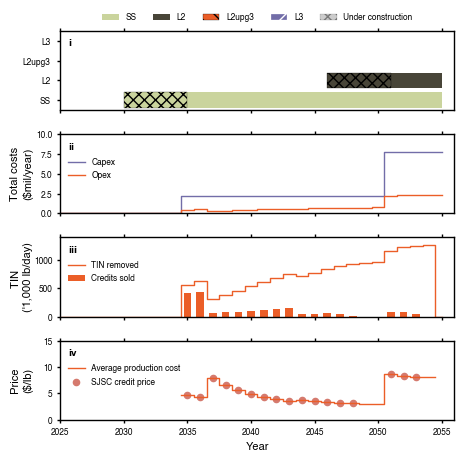

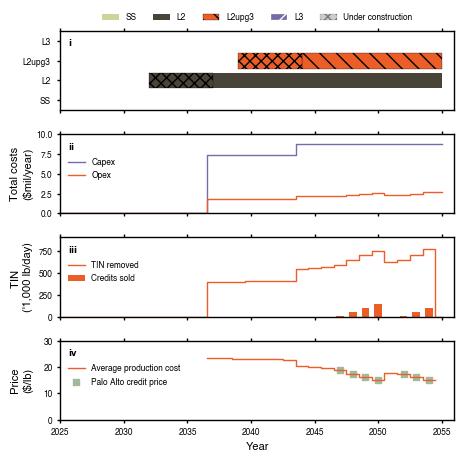

In [26]:
fig_SJSC_FC = plot_FC_capabilities('SJSC', lim_treated=1400, lim_cost=10, lim_price=15)
fig_PA_FC = plot_FC_capabilities('Palo Alto', lim_treated=900, lim_cost=10, lim_price=30)
#fig_SV_FC = plot_FC_capabilities('Sunnyvale', lim_treated=10, lim_cost=1, lim_price=10)


In [39]:
color_NC = '#484538'
color_FC = color_total
markers = {'SJSC':'o', 'Sunnyvale':'^', 'Palo Alto':'s'}
colors_WWTP = {'Sunnyvale': '#B79BB8', 'SJSC': '#D57A6E', 'Palo Alto': '#A3B89C'}

def avoided_cost(WWTP, df_NC=df_NC, df_FC=df_FC, lim_cost=15, lim_bought=500, lim_avoided=350):
    """
    Four-subplot figure comparing the No-Coordination (NC) and Full-Coordination
    (FC) market scenarios for a single WWTP.
    All subplots share an integer-year x-axis so the schedule rectangles
    (drawn at integer year coordinates) align with the step/bar plots.
      [0] Upgrade schedule — NC (bottom four rows) vs FC (top four rows)
      [1] Total cost (capex + opex, NPV $mil/year) — NC vs FC
      [2] Credits bought ('1,000 lb/day) — NC vs FC
      [3] Avoided cost ($/lb) = (NC total cost − FC total cost) / FC credits bought
    """
    fig, axs = plt.subplots(4, 1, figsize=(140/25.4, 120/25.4))

    df_w_NC = df_NC[df_NC['WWTP'] == WWTP].copy()
    df_w_FC = df_FC[df_FC['WWTP'] == WWTP].copy()
    years   = pd.to_datetime(df_w_NC['Year']).dt.year.values

    # ── Subplot 0: Schedule — NC vs FC ──────────────────────────────────────
    # Rectangles are drawn at integer year positions; x-axis must stay integer
    # NC occupies rows [0, len(Ls)), FC occupies rows [len(Ls), 2*len(Ls))
    for df_w, y_offset in [(df_w_NC, 0), (df_w_FC, len(Ls))]:
        for j, L in enumerate(Ls):
            y_pos = y_offset + j

            # ── Operational patch (solid fill) ──
            col_built = f'{L}_built'
            if col_built in df_w.columns:
                sched = df_w[col_built].values
                if sched.sum() > 0:
                    start = years[sched.argmax()]
                    end   = years[sched.nonzero()[0][-1]]
                    axs[0].add_patch(Rectangle(
                        (start, y_pos - 0.4), end - start, 0.8,
                        facecolor=custom_colors[L],
                        hatch=custom_hatches[L],
                        edgecolor=custom_edgecolor[L],
                        lw=0.2
                    ))

            # ── Construction patch (hatched, right before operational) ──
            col_const = f'{L}_construction'
            if col_const in df_w.columns:
                under_construction = df_w[col_const].values
                if under_construction.sum() > 0:
                    c_start = years[under_construction.argmax()]
                    c_end   = years[under_construction.nonzero()[0][-1]]
                    axs[0].add_patch(Rectangle(
                        (c_start, y_pos - 0.4), c_end - c_start + 1, 0.8,
                        facecolor=custom_colors[L],
                        alpha=1,
                        hatch='xxxx',
                        edgecolor='black',
                        lw=0.2
                    ))

    legend_handles = [
        Patch(facecolor=custom_colors[L], hatch=custom_hatches[L],
              edgecolor=custom_edgecolor[L], linewidth=0.2, label=L)
        for L in Ls
    ] + [
        Patch(facecolor='grey', alpha=0.4, hatch='xxx',
              edgecolor='black', linewidth=0.2, label='Under construction')
    ]
    axs[0].legend(
        handles=legend_handles,
        loc='lower center', bbox_to_anchor=(0.5, 1.02),
        ncol=len(Ls) + 1, frameon=False,
        prop={'family': 'Helvetica', 'size': leg_size}
    )
    axs[0].axhline(len(Ls) - 0.5, color='black', linewidth=0.5, linestyle=':')
    axs[0].set_ylim(-1, 2 * len(Ls))
    axs[0].set_yticks([(len(Ls) - 1) / 2, len(Ls) + (len(Ls) - 1) / 2])
    axs[0].set_yticklabels(['No market', 'Market'], **hfont)
    axs[0].tick_params(axis='y', pad=5)

    # ── Subplot 1: Total cost (capex + opex) ────────────────────────────────
    total_cost_NC = df_w_NC['Annual_capex'].values + df_w_NC['Annual_opex'].values
    total_cost_FC = df_w_FC['Annual_capex'].values + df_w_FC['Annual_opex'].values
    axs[1].step(years, np.append(total_cost_NC[:-1], total_cost_NC[-2]), '-',
                color=color_NC, label='NC', where='mid', linewidth=line_wid)
    axs[1].step(years, np.append(total_cost_FC[:-1], total_cost_FC[-2]), '-',
                color=color_FC, label='FC', where='mid', linewidth=line_wid)
    for year in years:
        print(f'Avoided cost for', WWTP, 'in year', year, ':',round(total_cost_NC[year - years[0]] - total_cost_FC[year - years[0]], 2), 'buying credits:', round(df_w_FC['Total_units_bought'].values[year - years[0]] * 30 / 1000), 'credit cost', round((total_cost_NC[year - years[0]] - total_cost_FC[year - years[0]]) * 1e6 / (df_w_FC['Total_units_bought'].values[year - years[0]] * 30), 2) if df_w_FC['Total_units_bought'].values[year - years[0]] > 0 else 'N/A')
    axs[1].set_ylabel('Cost of compliance\n($mil/year)', **hfont)
    axs[1].set_ylim(0, lim_cost)
    axs[1].legend(loc='lower left', frameon=False,
                  bbox_to_anchor=(0, 0.05), prop={'family': 'Helvetica', 'size': leg_size})

    # ── Subplot 2: Credits bought ('1,000 lb/day) ───────────────────────────
    # Total_units_bought is a lb/day rate; *30 converts it to lbs, /1000 to '1,000 lb
    bought_NC = df_w_NC['Total_units_bought'].values * 30 / 1000
    bought_FC = df_w_FC['Total_units_bought'].values * 30 / 1000
    bar_width = 0.6
    axs[2].bar(years, bought_FC, width=bar_width, color=color_FC)
    axs[2].set_ylabel("Credits bought\n('1,000 lb/day)", **hfont)
    axs[2].set_ylim(0, lim_bought)

    # ── Subplot 3: Avoided cost ($/lb) ──────────────────────────────────────
    # (NC total cost - FC total cost) [$mil] / FC credits bought [lb]
    bought_FC_lb = df_w_FC['Total_units_bought'].values * 30
    with np.errstate(divide='ignore', invalid='ignore'):
        avoided = np.where(bought_FC_lb > 0,
                            (total_cost_NC - total_cost_FC) * 1e6 / bought_FC_lb,
                            np.nan)
    axs[3].scatter(years, avoided,
                color=colors_WWTP[WWTP], marker=markers[WWTP], s=20)
    axs[3].axhline(0, color='black', linewidth=0.5, linestyle='--')
    axs[3].set_ylabel('Avoided cost\n($/lb)', **hfont)
    axs[3].set_ylim(0, lim_avoided)
    axs[3].set_xlabel('Year', **hfont)

    # ── Shared integer-year x-axis formatting ───────────────────────────────
    # All 4 subplots now use integer years so limits and ticks are consistent
    x_lo    = years[0]
    x_hi    = years[30] + 1
    x_ticks = np.arange(years[0], years[30] + 1, 5)

    x_label_coord = -0.07
    fig_labels    = ['i', 'ii', 'iii', 'iv']
    for i, ax in enumerate(axs):
        ax.set_xlim(x_lo, x_hi)
        ax.set_xticks(x_ticks)
        if i == len(axs) - 1:
            ax.set_xticklabels(x_ticks, **hfont_ticks)
        else:
            ax.set_xticklabels([])
        ax.yaxis.set_label_coords(x_label_coord, 0.5)
        ax.text(0.02, 0.9, fig_labels[i], transform=ax.transAxes,
                fontsize=leg_size, fontweight='bold', va='top', ha='left')
        ax.xaxis.set_ticks_position('both')
        ax.tick_params(axis='both', which='major', labelsize=leg_size,
                       labelfontfamily='Helvetica')
        ax.tick_params(axis='both', width=line_wid, length=bord_wid)
        for spine in ax.spines.values():
            spine.set_linewidth(line_wid)

    axs[0].set_yticklabels(['No market', 'Market'], **hfont)
    fig.tight_layout()
    plt.show()
    fig.savefig(f'{file}/avoided_cost_{WWTP}.svg', dpi=300, bbox_inches='tight')
    return fig


Avoided cost for SJSC in year 2025 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for SJSC in year 2026 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for SJSC in year 2027 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for SJSC in year 2028 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for SJSC in year 2029 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for SJSC in year 2030 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for SJSC in year 2031 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for SJSC in year 2032 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for SJSC in year 2033 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for SJSC in year 2034 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for SJSC in year 2035 : -0.28 buying credits: 0 credit cost N/A
Avoided cost for SJSC in year 2036 : -0.29 buying credits: 0 credit cost N/A
Avoided cost for SJSC in year 2037 : -0.04 buying credits: 0 credit cost N/A
Avoided cost for SJ

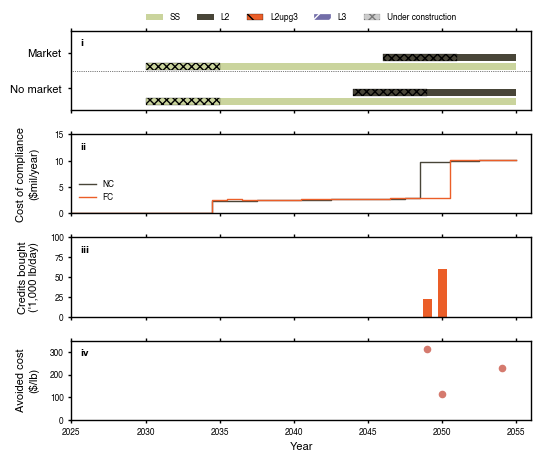

Avoided cost for Palo Alto in year 2025 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Palo Alto in year 2026 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Palo Alto in year 2027 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Palo Alto in year 2028 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Palo Alto in year 2029 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Palo Alto in year 2030 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Palo Alto in year 2031 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Palo Alto in year 2032 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Palo Alto in year 2033 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Palo Alto in year 2034 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Palo Alto in year 2035 : 10.78 buying credits: 420 credit cost 25.68
Avoided cost for Palo Alto in year 2036 : 10.78 buying credits: 433 credit cost 24.92
Avoided cost for Palo Alto i

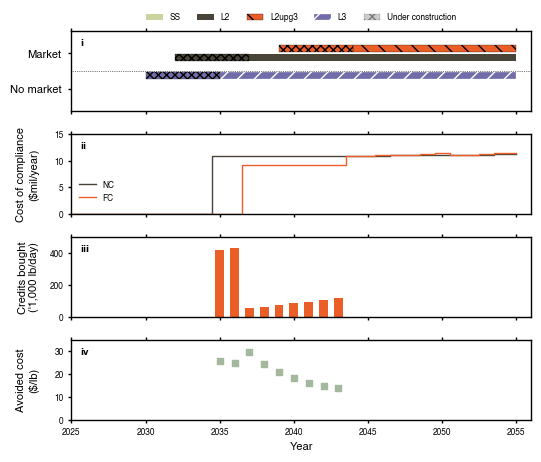

Avoided cost for Sunnyvale in year 2025 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Sunnyvale in year 2026 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Sunnyvale in year 2027 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Sunnyvale in year 2028 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Sunnyvale in year 2029 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Sunnyvale in year 2030 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Sunnyvale in year 2031 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Sunnyvale in year 2032 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Sunnyvale in year 2033 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Sunnyvale in year 2034 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Sunnyvale in year 2035 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Sunnyvale in year 2036 : 0.0 buying credits: 0 credit cost N/A
Avoided cost for Sunnyvale in year 2037 

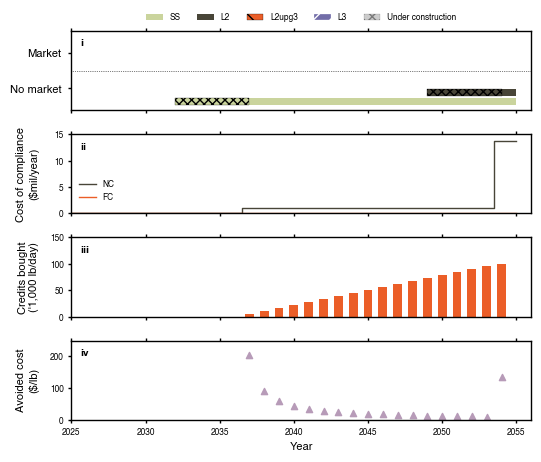

In [40]:
fig_SJSC_avoided = avoided_cost('SJSC', lim_cost=15, lim_bought=100, lim_avoided=350)
fig_PA_avoided = avoided_cost('Palo Alto', lim_cost=15, lim_bought=500, lim_avoided=35)
fig_SV_avoided = avoided_cost('Sunnyvale', lim_cost=15, lim_bought=150, lim_avoided=250)
